In [1]:
# REQUIRES, IMPORTS, ETC.
# =======================
# System
# ------
# import sys
import time
import importlib

# Third-party libraries
# ----------------------
import pandas as pd
import polars as pl

# MODULES
# ========
# System
# --------------
from pathlib import Path
from typing import Dict

# Custom
# Types, Defines
# --------------
import src.config.ctypes as ctp
importlib.reload(ctp)

import src.config.globals as glb
importlib.reload(glb)
from src.config.globals import *

# Helpers functions
# -----------------
import src.helpers.validations as val
importlib.reload(val)
import src.helpers.console as csl
importlib.reload(csl)
import src.helpers.charts as cht
importlib.reload(cht)
import src.helpers.bdorchestrator as bdo
importlib.reload(bdo)

<module 'src.helpers.bdorchestrator' from '/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/bdorchestrator.py'>

In [7]:
# CHECK CHANGES OF IMPORT FILES
# ==============================
import importlib
importlib.reload(ctp)
importlib.reload(csl)
importlib.reload(cht)
importlib.reload(val)
importlib.reload(bdo)

print(csl.__file__)
print([name for name in dir(ctp)])
print("+ ")

print(csl.__file__)
print([name for name in dir(csl)])
print("+ ")

print(cht.__file__)
print([name for name in dir(cht)])
print("+ ")

print(val.__file__)
print([name for name in dir(val)])

print(bdo.__file__)
print([name for name in dir(bdo)])

/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/console.py
['AggFunc', 'BigDataLib', 'ChartType', 'CleanStep', 'ErrorInfo', 'ErrorResponse', 'FilterOp', 'IssueAction', 'IssueType', 'Literal', 'TypeAlias', 'TypedDict', '__annotations__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/console.py
['LineBreak', 'SectionBegin', 'SectionBreak', 'SectionEnd', 'SectionErrEndAndExit', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'nbsp', 'sys', 'time']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/charts.py
['BarCht', 'ChartType', 'Dict', 'DifferenceCht', 'DuplicatedCht', 'HistogramCht', 'LineCht', 'PlotSalesAnalytics', 'QualityCht', 'RelationalScatterCht', 'ResidualsScatterCht', 'ScatterCht', 'SequentialScatterCht', 'S

In [3]:
# GLOBAL VARIABLES, PATHS
# =======================
# Current file paths
# ------------------
NOTEBOOK_DIR = Path.cwd()
DATA_DIR = (NOTEBOOK_DIR.parent / "data").resolve()
ML20_DIR = (NOTEBOOK_DIR.parent / "data" / "ml-20m").resolve()

# Global variables definition for this notebook
# ---------------------------------------------
mvDataset: str = ML20_DIR / "movies.csv"
rtDataset: str = ML20_DIR / "ratings.csv"

# Pandas dataframe to hold the dataset
df: pd.DataFrame
# Algorithm result
res: Dict[str, any]

In [4]:
# LIBRARIES COMPARISON, 4.1.1 LOAD SOURCE DATASET (from CSV file)
# ===============================================================
tInit: float = time.time()
csl.SectionBegin("LIBRARIES COMPARISON, 4.1.1 LOAD SOURCE DATASET (from CSV file)\n+ Loading Movies & Ratings Datasets", 0)

try:
  # a. PANDAS::LOAD DATASET
  mvDfPd = bdo.BigDataOrchestrator.CleanMoviesData('pandas', 
    bdo.BigDataOrchestrator.LoadDataset('pandas', str(mvDataset), pPrintResult=False)['data'], 3
  )['data']
  rtDfPd: pd.DataFrame = bdo.BigDataOrchestrator.LoadDataset('pandas', str(rtDataset))['data']

  # b. POLARS::LOAD DATASET
  mvDfPl = bdo.BigDataOrchestrator.CleanMoviesData('polars', 
    bdo.BigDataOrchestrator.LoadDataset('polars', str(mvDataset), pPrintResult=False)['data'], 3
  )['data']
  rtDfPl: pl.DataFrame = bdo.BigDataOrchestrator.LoadDataset('polars', str(rtDataset))['data']

except Exception as e:
  csl.SectionErrEndAndExit(e.args[0], tInit)

+ =========================================================
+ LIBRARIES COMPARISON, 4.1.1 LOAD SOURCE DATASET (from CSV file)
+ Loading Movies & Ratings Datasets
+ ---------------------------------------------------------
Executing operation with PANDAS...
 
Movies dataset cleaned ('year' extracted) successfully. Execution time: 0.0888 seconds
Total rows: 27255
First 3 rows of the dataset:
   movieId             title                                       genres  \
0        1         Toy Story  Adventure|Animation|Children|Comedy|Fantasy   
1        2           Jumanji                   Adventure|Children|Fantasy   
2        3  Grumpier Old Men                               Comedy|Romance   

   year  
0  1995  
1  1995  
2  1995  
+ ---------------------------------------------------------
Executing operation with PANDAS...
 
File loaded: /home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/activities/RA3/lesson_04/data/ml-20m/ratings.csv
 successfully. Execution

In [5]:
# LIBRARIES COMPARISON, 4.1.2a BASIC OPERATIONS: FILTERING
# =========================================================
csl.SectionBegin("LIBRARIES COMPARISON, 4.1.2a FILTERING\n+ Movies (2000 <= year) & Ratings (4 <= rating)", 0)

try:
  # a. PANDAS::FILTER & JOIN
  tInitPd: float = time.perf_counter()
  fltDfPd: pd.DataFrame = pd.merge(
    bdo.BigDataOrchestrator.FilterData('pandas', mvDfPd, 'year', '>=', 2000, pPrintResult=False)['data'], 
    bdo.BigDataOrchestrator.FilterData('pandas', rtDfPd, 'rating', '>=', 4, pPrintResult=False)['data'], 
    on='movieId', how='inner'
  )

  csl.SectionBreak(0, 0)
  print(f"Executing operation with PANDAS...")
  csl.nbsp()
  print(fltDfPd.head(3))
  csl.nbsp()
  print(f"Filtered successfully. Dataset total rows: {len(fltDfPd)}")
  print(f"Execution time: {time.perf_counter() - tInitPd:.4f} seconds")

  # b. POLARS::FILTER & JOIN
  tInitPl: float = time.perf_counter()
  fltDfPl: pl.DataFrame = bdo.BigDataOrchestrator.FilterData('polars', mvDfPl, 'year', '>=', 2000, pPrintResult=False)['data'].join(
     bdo.BigDataOrchestrator.FilterData('polars', rtDfPl, 'rating', '>=', 4, pPrintResult=False)['data'], on='movieId', how='inner'
  )

  csl.SectionBreak(0, 0)
  print(f"Executing operation with POLARS...")
  csl.nbsp()
  print(fltDfPl.head(3))
  csl.nbsp()
  print(f"Filtered successfully. Dataset total rows: {len(fltDfPl)}")
  print(f"Execution time: {time.perf_counter() - tInitPl:.4f} seconds")

except Exception as e:
  csl.SectionErrEndAndExit(e.args[0], tInit)

csl.SectionEnd(0)

+ =========================================================
+ LIBRARIES COMPARISON, 4.1.2a FILTERING
+ Movies (2000 <= year) & Ratings (4 <= rating)
+ ---------------------------------------------------------
Executing operation with PANDAS...
 
   movieId       title       genres  year  userId  rating   timestamp
0     2769  Yards, The  Crime|Drama  2000     156     4.0  1046895842
1     2769  Yards, The  Crime|Drama  2000    1358     5.0   973554543
2     2769  Yards, The  Crime|Drama  2000    2196     4.0   996462288
 
Filtered successfully. Dataset total rows: 2500965
Execution time: 1.9700 seconds
+ ---------------------------------------------------------
Executing operation with POLARS...
 
shape: (3, 7)
┌─────────┬─────────────────────┬────────────────────────────┬──────┬────────┬────────┬────────────┐
│ movieId ┆ title               ┆ genres                     ┆ year ┆ userId ┆ rating ┆ timestamp  │
│ ---     ┆ ---                 ┆ ---                        ┆ ---  ┆ ---    

In [6]:
# LIBRARIES COMPARISON, 4.1.2b BASIC OPERATIONS: SORTING
# ======================================================
tInit: float = time.time()
sortCols: list[str] = ['year', 'rating', 'movieId', 'userId']
sortDirs: list[bool] = [False, False, True, True]

csl.SectionBegin( f"LIBRARIES COMPARISON, 4.1.3 SORTING\n+ Sort by: {sortCols} | Ascending: {sortDirs}", 0)

try:

  # a. PANDAS::SORT DATA
  srtDfPd: pd.DataFrame = bdo.BigDataOrchestrator.SortData(
    'pandas',
    fltDfPd,
    sortCols,
    sortDirs,
    pPreviewRows=3
  )['data']

  # b. POLARS::SORT DATA
  srtDfPl: pl.DataFrame = bdo.BigDataOrchestrator.SortData(
    'polars',
    fltDfPl,
    sortCols,
    sortDirs,
    pPreviewRows=3
  )['data']

except Exception as e:
  csl.SectionErrEndAndExit(e.args[0], tInit)

csl.SectionEnd(0)

+ =========================================================
+ LIBRARIES COMPARISON, 4.1.3 SORTING
+ Sort by: ['year', 'rating', 'movieId', 'userId'] | Ascending: [False, False, True, True]
+ ---------------------------------------------------------
Executing operation with PANDAS...
 
Data sorted by ['year', 'rating', 'movieId', 'userId'] successfully. Execution time: 0.8711 seconds
Total rows: 2500965
First 3 rows of the dataset:
   movieId              title                   genres  year  userId  rating  \
0   113345  Jupiter Ascending  Action|Adventure|Sci-Fi  2015   19089     5.0   
1   113345  Jupiter Ascending  Action|Adventure|Sci-Fi  2015   41852     5.0   
2   113345  Jupiter Ascending  Action|Adventure|Sci-Fi  2015   98139     5.0   

    timestamp  
0  1425219438  
1  1424739035  
2  1427469523  
+ ---------------------------------------------------------
Executing operation with POLARS...
 
Data sorted by ['year', 'rating', 'movieId', 'userId'] successfully. Execution time

In [10]:
# LIBRARIES COMPARISON, 4.1.2c BASIC OPERATIONS: AGGREGATION
# =========================================================
tInit: float = time.time()
groupCols: list[str] = ['year', 'movieId', 'title']
targetCol: str = 'rating'
aggOperation: str = 'mean'
aliasCol: str = 'avg_rating'

csl.SectionBegin(f"LIBRARIES COMPARISON, 4.1.2c AGGREGATION\n+ Group by: {groupCols}\n+ Operation: {aggOperation}('{targetCol}') as '{aliasCol}'", 0)

try:
  # a. PANDAS::AGGREGATE DATA
  aggDfPd: pd.DataFrame = bdo.BigDataOrchestrator.AggregateData(
    'pandas',
    srtDfPd,
    groupCols,
    targetCol,
    aggOperation,
    aliasCol,
    pPreviewRows=3
  )['data']

  # b. POLARS::AGGREGATE DATA
  aggDfPl: pl.DataFrame = bdo.BigDataOrchestrator.AggregateData(
    'polars',
    srtDfPl,
    groupCols,
    targetCol,
    aggOperation,
    aliasCol,
    pPreviewRows=3
  )['data']

except Exception as e:
  csl.SectionErrEndAndExit(e.args[0], tInit)

csl.SectionEnd(0)

+ =========================================================
+ LIBRARIES COMPARISON, 4.1.2c AGGREGATION
+ Group by: ['year', 'movieId', 'title']
+ Operation: mean('rating') as 'avg_rating'
+ ---------------------------------------------------------
Executing operation with PANDAS...
 
Data aggregated by ['year', 'movieId', 'title'] (mean of 'rating') successfully. Execution time: 0.3579 seconds
Total rows: 9735
First 3 rows of the dataset:
   year  movieId        title  avg_rating
0  2000     2769   Yards, The    4.218750
1  2000     3177  Next Friday    4.247292
2  2000     3190    Supernova    4.153409
+ ---------------------------------------------------------
Executing operation with POLARS...
 
Data aggregated by ['year', 'movieId', 'title'] (mean of 'rating') successfully. Execution time: 0.1598 seconds
Total rows: 9735
First 3 rows of the dataset:
shape: (3, 4)
┌──────┬─────────┬─────────────┬────────────┐
│ year ┆ movieId ┆ title       ┆ avg_rating │
│ ---  ┆ ---     ┆ ---      

In [22]:
# DATA ANALYSIS, 4. CHECK OF INVALID DATE VALUES
# ==============================================
tInit: float = time.time()

# CheckInvalidDates
# -----------------
# Try to convert the date column to proper datetime format
# errors='coerce' converts all invalid dates to NaN
# 
# @param string pColumn Name of the column to convert to proper date format
# @return None
def CheckInvalidDates(pDf: pd.DataFrame, pColumn:str = 'fecha') -> Dict[str, any]:
  properDateTime: pd.Series = pd.to_datetime(pDf[pColumn], errors='coerce')
  
  # How many dates were successfully converted and how many failed
  totRows: int = len(pDf)
  totProperDates: int = properDateTime.notna().sum()
  totInvalidDates: int = properDateTime.isna().sum()

  print(f"Total rows: {totRows}")
  print(f"Valid dates converted successfully: {totProperDates}")
  print(f"Invalid or null dates detected: {totInvalidDates}")

  # Show some of the rows with dates that failed
  print("\nSnapshot of rows with invalid dates:")
  print(pDf[properDateTime.isna()][pColumn].head(10))

  return {
    'category': pColumn,
    'total': totRows,
    'valid': totProperDates,
    'errors': totInvalidDates
  }

  
# Execute script
csl.SectionBegin("CHECK OF INVALID DATE VALUES", 0)
print("+ Summary of conversion date column state:")
csl.SectionBreak(0,0)

resInvalidDates: Dict[str, any] = CheckInvalidDates(df, "fecha")

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ CHECK OF INVALID DATE VALUES
+ Summary of conversion date column state:
+ ---------------------------------------------------------
Total rows: 320
Valid dates converted successfully: 302
Invalid or null dates detected: 18

Snapshot of rows with invalid dates:
0             NaN
1             NaN
2             NaN
3             NaN
4             NaN
25     2026-02-30
26     2026-13-10
27     2026-10-45
28    no_es_fecha
29     31/02/2026
Name: fecha, dtype: str
+ ---------------------------------------------------------
+ Time to load: 0.0060 seconds
+ =========================================================


In [23]:
# DATA ANALYSIS, 5. CHECK OF INVALID NUMERIC VALUES
# =================================================
tInit: float = time.time()

# CheckInvalidNumericValues
# -------------------------
# Convert columns to numeric and check for invalid values
# 
# @param pd.DataFrame pDf The pandas dataframe to check
# @return list[dict] Validation results for each numeric column
def CheckInvalidNumericValues(pDf: pd.DataFrame) -> list[dict]:
  # Convert to numeric by forcing errors to NaN values for security
  pDf['cantidad_num'] = pd.to_numeric(pDf['cantidad'], errors='coerce')
  pDf['precio_unitario_num'] = pd.to_numeric(pDf['precio_unitario'], errors='coerce')
  pDf['total_num'] = pd.to_numeric(pDf['total'], errors='coerce')

  # Identify rows with invalid values (null, non-numeric, zero or negative)
  invalidPrices: pd.Series = pDf['precio_unitario_num'].isna() | (pDf['precio_unitario_num'] <= 0)
  invalidAmount: pd.Series = pDf['cantidad_num'].isna() | (pDf['cantidad_num'] <= 0)
  invalidTotales: pd.Series = pDf['total_num'].isna() | (pDf['total_num'] <= 0)

  # Identify rows with at least one invalid numeric value
  invalidRows: pd.DataFrame = pDf[invalidAmount | invalidPrices | invalidTotales]

  # Show summary of results
  print(f"Rows with some invalid numeric values: {len(invalidRows)}")
  print(f"Rows with invalid [precio_unitario]:  {int(invalidPrices.sum())}")
  print(f"Rows with invalid [cantidad]:         {int(invalidAmount.sum())}")
  print(f"Rows with invalid [total]:            {int(invalidTotales.sum())}")

  csl.SectionBreak(0,0)
  print("Snapshot of rows with invalid numeric values:")
  print(invalidRows[['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']].head(10))

  # Prepare results for the quality summary chart
  totRows: int = len(pDf)
  res: list[dict] = []

  for col, mask in [
    ('cantidad', invalidAmount),
    ('precio_unitario', invalidPrices),
    ('total', invalidTotales)
  ]:
    totErrors: int = int(mask.sum())
    res.append({
      'category': col,
      'total': totRows,
      'valid': totRows - totErrors,
      'errors': totErrors
    })
    
  return res
  
csl.SectionBegin("CHECK OF NEGATIVE OR ZERO NUMERIC VALUES", 0)
print("+ Summary of rows with weird numeric values:")
csl.SectionBreak(0,0)

resNumericValues: list[dict] = CheckInvalidNumericValues(df)

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ CHECK OF NEGATIVE OR ZERO NUMERIC VALUES
+ Summary of rows with weird numeric values:
+ ---------------------------------------------------------
Rows with some invalid numeric values: 45
Rows with invalid [precio_unitario]:  15
Rows with invalid [cantidad]:         16
Rows with invalid [total]:            35
+ ---------------------------------------------------------
Snapshot of rows with invalid numeric values:
         fecha               producto  cantidad  precio_unitario   total
10  2026-10-07       Teclado mecanico       NaN           103.59  310.77
11  2026-09-22  Auriculares Bluetooth       NaN            95.82   95.82
12  2026-10-11              Webcam HD       NaN            24.36   24.36
13  2026-10-12          Disco SSD 1TB       NaN           140.97  281.94
14  2026-10-02          Disco SSD 1TB       NaN           135.78  271.56
15  2026-10-04        Cargador rapido       1.0              NaN   36.46
16  2026-1

+ =========================================================
+ CHART: CHECK OF INVALID VALUES (DATES, NUMERIC)
+ ---------------------------------------------------------


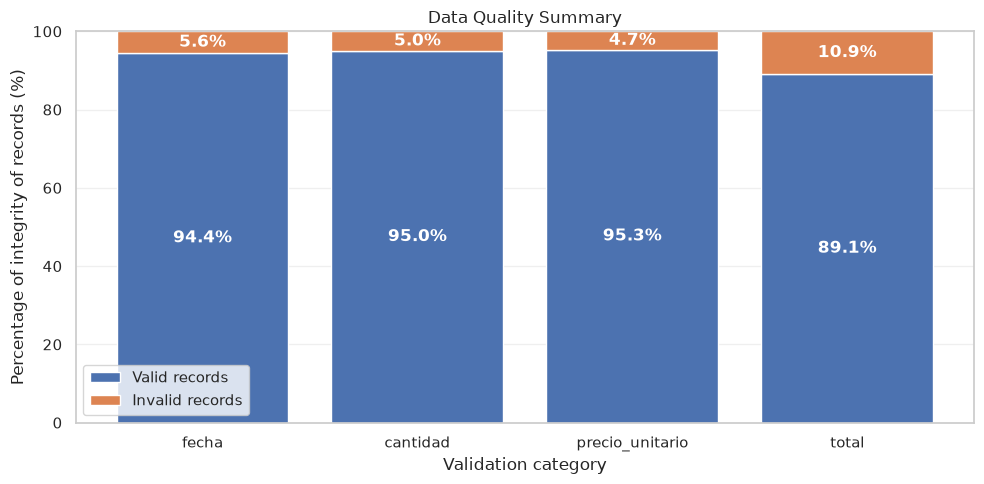

+ ---------------------------------------------------------
+ Time to load: 0.3266 seconds
+ =========================================================


In [24]:
# DATA ANALYSIS, 6. CHECK OF INVALID VALUES (DATES, NUMERIC)
# ==========================================================
tInit: float = time.time()

csl.SectionBegin("CHART: CHECK OF INVALID VALUES (DATES, NUMERIC)", 0)
csl.SectionBreak(0,0)

res = cht.PlotSalesAnalytics((
  [resInvalidDates] + resNumericValues
  ), {
    'figsize': (10, 5),
    'title': 'Data Quality Summary',
    'xlabel': 'Validation category',
    'ylabel': 'Percentage of integrity of records (%)',
    'fontsize': 12,
    'fontweight': 'bold',
  }, 
  'quality'
)

if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)


+ =========================================================
+ CHECK OF OUTLIERS VALUES
+ Summary of rows with possible outlier values on Price and Quantity:
+ ---------------------------------------------------------
Quantity highest values: 5
 
          fecha          producto  cantidad  precio_unitario     total
97   2026-10-15  Altavoz portatil     845.0           117.16  99000.20
94   2026-10-07  Teclado mecanico     794.0            44.07  34991.58
100  2026-09-25     Disco SSD 1TB     394.0           107.57  42382.58
96   2026-09-26      Funda tablet     315.0            18.08   5695.20
95   2026-09-29         Webcam HD     304.0            69.97  21270.88
+ ---------------------------------------------------------
Price highest values: 5
 
          fecha             producto  cantidad  precio_unitario     total
104  2026-09-29     Teclado mecanico       1.0          11922.0   11922.0
102  2026-10-08    Raton inalambrico       2.0          11838.0   23676.0
103  2026-09-19     

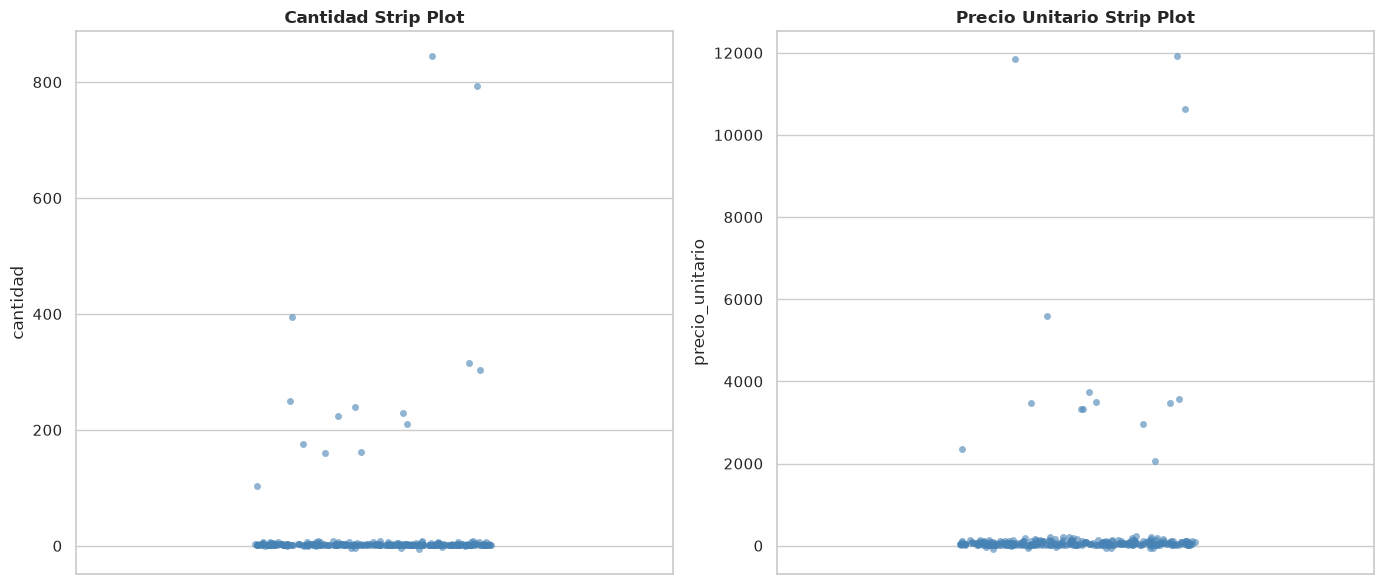

+ ---------------------------------------------------------
+ Time to load: 0.3470 seconds
+ =========================================================


In [25]:
# DATA ANALYSIS, 7. CHECK OF OUTLIERS VALUES
# ==========================================
tInit: float = time.time()

# CheckOutliersValues
# -------------------
# Convert columns ensuring numeric values and show the biggest 
# values to detect prices or quantities that makes no sense
# 
# @param pd.DataFrame pDf The pandas dataframe to check
# @return None
def CheckOutliersValues(pDf: pd.DataFrame) -> None:
  # Ensure numeric conversion
  pDf['qty_temp'] = pd.to_numeric(pDf['cantidad'], errors='coerce')
  pDf['prc_temp'] = pd.to_numeric(pDf['precio_unitario'], errors='coerce')
  
  # Show the highest values
  highestQty = pDf.nlargest(5, 'qty_temp')
  print(f"Quantity highest values: {len(highestQty)}")
  csl.nbsp()
  print(highestQty[['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']].head(5))
  csl.SectionBreak(0,0)

  highestPrc = pDf.nlargest(5, 'prc_temp')
  print(f"Price highest values: {len(highestPrc)}")
  csl.nbsp()
  print(highestPrc[['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']].head(5))
  
  # Show type chart Line Plot to check Outliers on Quantity and Price
  # Shared base configuration Chart
  baseCfgCharts: dict = {
    "ncols": 2,
    "figsize": (14, 6),
    "color": "steelblue",
    "fontweight": "bold",
    "fontsize": 12
  }
  
  # Histogram Plot Chart
  # cfgCurrPlotChart: Dict[str, any] = baseCfgCharts | { 'alpha': .6, 'bins': 30, 'kde': True }
  # cht.PlotSalesAnalytics(pDf, ['cantidad', 'precio_unitario'], cfgCurrPlotChart, 'histogram')
  
  # Line Plot Chart
  # cfgCurrPlotChart: Dict[str, any] = { 'alpha': .8, 'linewidth': 1.5 }
  # cht.PlotSalesAnalytics(pDf, ['cantidad', 'precio_unitario'], cfgCurrPlotChart, 'line')
  
  # Scatter Plot Chart
  # cfgCurrPlotChart: Dict[str, any] = baseCfgCharts | {'mode': 'seq', 'alpha': .6, 'size': 30 }
  # cht.PlotSalesAnalytics(pDf, ['cantidad', 'precio_unitario'], cfgCurrPlotChart, 'scatter')
  
  # Strip Plot Chart
  cfgCurrPlotChart: Dict[str, any] = baseCfgCharts | { 'alpha': .6, 'jitter': .2, 'size': 5 }
  cht.PlotSalesAnalytics(['cantidad', 'precio_unitario'], cfgCurrPlotChart, 'strip', pDf)
  
csl.SectionBegin("CHECK OF OUTLIERS VALUES", 0)
print("+ Summary of rows with possible outlier values on Price and Quantity:")
csl.SectionBreak(0,0)
CheckOutliersValues(df)
csl.SectionBreak(0,0)

tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)